尽管```7_POS_model_retest.ipynb```笔记本的测试结果表明，在使用滞后的宏观因子进行回归之后，宏观因子将失去绝大部分的解释力度，但本笔记本将仍然进行首次POS模拟，用于检验后续模拟是否仍然保持解释程度不变。本笔记本使用 `data/3_POS_prediction/` 进行 2025-01-01 至 2026-06-30 的逐日 POS 模拟。初始训练窗口为 2012-01-01 至 2024-12-31，之后每天执行“预测、记录实际误差、加入新观察、重新回归”。

Although the test results from the `7_POS_model_retest.ipynb` notebook indicate that, after using lagged macro factors for regression, the macro factors will lose most of their explanatory power, this notebook will still conduct the initial POS simulation to examine whether the explanatory power remains stable in subsequent simulations. This notebook uses `data/3_POS_prediction/` to conduct a daily POS simulation from 2025-01-01 to 2026-06-30. The initial training window is from 2012-01-01 to 2024-12-31. Subsequently, a daily recursive loop of "predict, record actual errors, incorporate new observations, and re-run the regression" will be executed.

In [9]:
# python import packages
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display, Markdown
from statsmodels.stats.multitest import multipletests

预测目标为 `USDSLE_daily`，即 `100 × [ln E(t) − ln E(t−1)]`。预测 t 日时仅使用 t−1 日及以前的信息：汇率和五个宏观因子均取前一天的值。第 7 个笔记本使用同期宏观因子，本笔记本按一日提前预测的设定重新估计初始模型。开头缺失不回填。

六个历史事件保留为已经发生日期的脉冲控制项，预测期的事件输入统一设为 0；本模型不预测新增政策冲击。三个年度指标的预测/实际标记随输入保留，用于追溯，不作为新增解释变量。日期和数值沿用已有文件，因此历史预测版本及发布日期假设的限制继续适用。

The target is the daily percentage log change in USDSLE. Forecasts for day t use FX and macro values from t−1. The initial model is re-estimated with this timing, rather than reusing the contemporaneous coefficients from notebook 7. Leading missing observations remain missing.

Six dated historical event pulses control for past events. Their inputs are zero during the forecast period; new policy shocks are not predicted. Forecast/actual source flags are retained for audit only. Results remain conditional on the supplied data vintages and release-date assumptions.


In [10]:
DATA = Path("data/3_POS_prediction")
if not DATA.is_dir():
    DATA = Path("../data/3_POS_prediction")
if not DATA.is_dir():
    raise FileNotFoundError("Run from the project root or notebook directory.")

# basic parameters and constants and restrictions settings
TRAIN_START, TRAIN_END = "2012-01-01", "2024-12-31"
POS_START, POS_END = "2025-01-01", "2026-06-30"
ALPHA, HAC_LAGS, ROLLING_OBSERVATIONS = 0.05, 12, 30
# Retain Sunday through Thursday; lag/window sizes count retained observations.
MODEL_DAY = pd.offsets.CustomBusinessDay(weekmask="Sun Mon Tue Wed Thu")
calendar = pd.date_range(TRAIN_START, POS_END, freq=MODEL_DAY)
pos_dates = pd.date_range(POS_START, POS_END, freq=MODEL_DAY)
FACTOR_FILES = {
    "CPI": "headline_cpi_log_change_daily.csv",
    "GDP growth change": "gdp_annual_pct_change_daily.csv",
    "Trade balance change": "trade_balance_annual_pct_change_daily.csv",
    "FX reserves": "fx_reserves_log_change_daily.csv",
    "Government debt / GDP": "general_government_gross_debt_annual_change_pp_daily.csv",
}
factors = list(FACTOR_FILES)

def read_daily(filename):
    frame = pd.read_csv(DATA / filename)
    frame.index = pd.to_datetime(frame.pop("date"), format="%Y/%m/%d")
    if frame.index.has_duplicates or not frame.index.is_monotonic_increasing:
        raise ValueError(f"Dates must be unique and sorted: {filename}")
    if not calendar.isin(frame.index).all():
        raise ValueError(f"Missing calendar dates: {filename}")
    frame = frame.reindex(calendar).apply(pd.to_numeric, errors="raise")
    if not np.isfinite(frame.to_numpy()[frame.notna().to_numpy()]).all():
        raise ValueError(f"Nonfinite numeric value: {filename}")
    return frame

factor_frames = {name: read_daily(file) for name, file in FACTOR_FILES.items()}
macro = pd.DataFrame({name: frame.iloc[:, 0] for name, frame in factor_frames.items()})
source_flags = pd.DataFrame({
    name: frame["is_prediction"] for name, frame in factor_frames.items()
    if "is_prediction" in frame
})
if not source_flags.stack().dropna().isin([0, 1]).all():
    raise ValueError("Source flags must be 0, 1, or missing.")
fx = read_daily("USDSLE_daily.csv").iloc[:, 0].rename("fx_change")
events = read_daily("Sierra_Leone_Policy_Event_Dummies_daily.csv")


In [11]:
# Identify historical event controls using only the initial training period.
event_groups = {}
for name in events:
    values = events.loc[:TRAIN_END, name]
    if not values.dropna().isin([0, 1]).all():
        raise ValueError(f"Event is not a 0/1 indicator: {name}")
    if values.nunique() > 1:
        event_groups.setdefault(tuple(values), []).append(name)
policy_X = pd.DataFrame(index=calendar)
policy_sources = {}
for pattern, names in event_groups.items():
    historical = events.loc[:TRAIN_END, names[0]]
    event_date = historical.index[historical.eq(1)][0]
    term = f"P_{event_date:%Y_%m_%d}"
    if term in policy_X:
        raise ValueError(f"Duplicate event term: {term}")
    policy_X[term] = 0.0
    policy_X.loc[historical.index, term] = historical.to_numpy()
    policy_sources[term] = " + ".join(names)


In [12]:
# All forecasting factors use the preceding retained observation's information.
continuous = ["fx_lag1", *factors]
predictors = pd.concat(
    [fx.shift(1).rename("fx_lag1"), macro.shift(1), policy_X], axis=1
)
sample = pd.concat([fx, predictors], axis=1).dropna()
if not pos_dates.isin(sample.index).all():
    raise ValueError("The POS period must contain complete model inputs and outcomes on every retained date.")
y_all = sample["fx_change"]
X_full = sm.add_constant(sample.drop(columns="fx_change"), has_constant="add")
initial_dates = sample.loc[:TRAIN_END].index
if initial_dates.empty or initial_dates[-1] != pd.Timestamp(TRAIN_END):
    raise ValueError("The initial sample must end on TRAIN_END.")

forecast_inputs = X_full.loc[pos_dates].copy()
forecast_inputs.insert(0, "feature_date", pd.DatetimeIndex([date - MODEL_DAY for date in pos_dates]))
for name in source_flags:
    forecast_inputs[f"is_prediction::{name}"] = source_flags[name].shift(1).loc[pos_dates]
if not forecast_inputs[list(policy_X)].eq(0).all().all():
    raise ValueError("Future event shocks must not be supplied to the forecast.")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:.6g}")
sample_summary = pd.DataFrame({
    "requested_training_start": [TRAIN_START],
    "effective_training_start": [initial_dates[0].strftime("%Y-%m-%d")],
    "training_end": [TRAIN_END],
    "initial_n": [len(initial_dates)],
    "POS_start": [POS_START],
    "POS_end": [POS_END],
    "forecast_days": [len(pos_dates)],
    "full_model_parameters": [X_full.shape[1]],
})
display(sample_summary)


,requested_training_start,effective_training_start,training_end,initial_n,POS_start,POS_end,forecast_days,full_model_parameters
0,2012-01-01,2013-06-19,2024-12-31,3010,2025-01-01,2026-06-30,390,13


下面估计初始完整模型和 AR(1) 基准模型，二者使用相同的非缺失日期。完整模型包含截距、汇率滞后项、五个滞后一天的宏观因子及六个历史事件；AR(1) 仅包含截距和汇率滞后项。

系数由 OLS 估计。HAC(12) 使用 Bartlett 权重、有限样本修正和渐近正态 z 检验；12 表示日度滞后。五个宏观因子的单项 p 值使用 Holm 校正，并保留五因子联合 Wald p 值。事件项仅记录系数。这里的 R² 和 p 值描述训练回归，后面的预测误差用于评价 POS 表现。

The full model and AR(1) benchmark use the same initial observations. OLS coefficients are paired with HAC(12) inference, Bartlett weights, finite-sample correction, and normal z-tests. Macro-factor p-values receive Holm correction; event coefficients are reported without significance claims. Training R² and p-values are kept separate from forecast accuracy.


In [13]:
MODEL_LABELS = {
    "full_expanding": "Full model, expanding",
    "ar1_expanding": "AR(1), expanding",
    "full_fixed": "Full model, fixed",
    "zero_change": "Zero change",
}

def fit_hac(response, design):
    if not response.index.equals(design.index):
        raise ValueError("Response and design dates differ.")
    return sm.OLS(response, design, missing="raise").fit(
        cov_type="HAC",
        cov_kwds={"maxlags": HAC_LAGS, "kernel": "bartlett", "use_correction": True},
        use_t=False,
    )

def macro_joint_p(fit):
    restrictions = np.eye(len(fit.params))[
        [fit.params.index.get_loc(name) for name in factors]
    ]
    return float(fit.wald_test(restrictions, use_f=False, scalar=True).pvalue)

def coefficient_table(fit, include_macro=False):
    terms = ["const", "fx_lag1", *factors] if include_macro else ["const", "fx_lag1"]
    ci = fit.conf_int(alpha=ALPHA).loc[terms]
    table = pd.DataFrame({
        "coefficient": fit.params.loc[terms],
        "HAC_SE": fit.bse.loc[terms],
        "p_HAC": fit.pvalues.loc[terms],
        "CI95_low": ci[0],
        "CI95_high": ci[1],
    })
    if include_macro:
        table["p_Holm_5_factors"] = np.nan
        table.loc[factors, "p_Holm_5_factors"] = multipletests(
            table.loc[factors, "p_HAC"], method="holm"
        )[1]
    return table

initial_full = fit_hac(y_all.loc[initial_dates], X_full.loc[initial_dates])
initial_ar1 = fit_hac(
    y_all.loc[initial_dates], X_full.loc[initial_dates, ["const", "fx_lag1"]]
)
display(coefficient_table(initial_full, include_macro=True))
display(coefficient_table(initial_ar1))
display(pd.DataFrame({
    "source_event": pd.Series(policy_sources),
    "coefficient": initial_full.params.loc[list(policy_sources)],
}))


,coefficient,HAC_SE,p_HAC,CI95_low,CI95_high,p_Holm_5_factors
const,-0.0106583,0.0168618,0.527325,-0.0437067,0.0223902,NaN
fx_lag1,-0.084305,0.0343696,0.0141712,-0.151668,-0.0169418,NaN
CPI,0.0278326,0.0157188,0.0766181,-0.00297571,0.0586409,0.306472
GDP growth change,0.00025139,9.27203e-05,0.00670268,6.9661e-05,0.000433118,0.0335134
Trade balance change,-6.6109e-05,0.000122936,0.590748,-0.000307059,0.000174841,1
FX reserves,0.00110599,0.0020612,0.59156,-0.00293388,0.00514586,1
Government debt / GDP,0.00338726,0.00371338,0.361675,-0.00389083,0.0106653,1


,coefficient,HAC_SE,p_HAC,CI95_low,CI95_high
const,0.056599,0.0183909,0.00208708,0.0205535,0.0926446
fx_lag1,-0.0210392,0.0704299,0.765149,-0.159079,0.117001


,source_event,coefficient
P_2015_11_16,D_IMF_ECF_REVIEW_2015,-0.157275
P_2016_06_23,D_Brexit referendum_2016,38.6428
P_2021_08_12,D_REDENOM_ANNOUNCE_2021,0.0681002
P_2021_08_23,D_SDR_ALLOCATION_2021,-0.0051201
P_2023_06_05,D_IMF_ECF_REVIEW_A_2023,-0.149826
P_2023_11_20,D_IMF_ECF_REVIEW_B_2023,-0.500756


每个预测日执行以下顺序：

1. 使用截至前一日训练得到的参数生成预测，同时保存预测起点、训练样本量和输入来源。
2. 读取当天实际汇率变化，计算误差 `actual − prediction`、绝对误差和平方误差。
3. 将当天观察加入训练窗口，重新估计完整模型和 AR(1)，保存更新后的参数与训练指标。

另外保留固定初始完整模型和零变化预测，全部模型使用相同的预测日期。固定模型仅固定参数，输入仍随日期更新。更新后的参数从下一天开始用于预测；最后一天的回归只作为下一步模型状态保存。点预测不加入随机白噪声。

参数轨迹以 `fit_through` 标明训练截止日期，`usable_from` 标明最早可用的预测日期。每日 HAC p 值用于描述，不按其是否跨过 0.05 反复选择模型。

Each day is predicted with the previous day's fitted model, scored after the actual outcome is observed, and then added to the expanding training window. The initial full model is also retained with fixed coefficients, alongside a zero-change forecast. Updated coefficients become available on the following day. No random noise is added to point forecasts.


In [14]:
def run_expanding_pos(response, design, target_dates, first_full, first_ar1):
    current_full, current_ar1 = first_full, first_ar1
    fit_through = pd.Timestamp(TRAIN_END)
    forecast_rows, training_rows, parameter_rows = [], [], []

    def save_fit_state(model_key, fit, end_date):
        training_rows.append({
            "fit_through": end_date,
            "usable_from": end_date + MODEL_DAY,
            "model": model_key,
            "n": int(fit.nobs),
            "parameters": len(fit.params),
            "training_R2": fit.rsquared,
            "training_adjusted_R2": fit.rsquared_adj,
            "training_RMSE": np.sqrt(np.mean(fit.resid ** 2)),
            "training_MAE": np.mean(np.abs(fit.resid)),
            "p_const_HAC": fit.pvalues["const"],
            "p_fx_lag1_HAC": fit.pvalues["fx_lag1"],
            "p_five_macro_joint_HAC": (
                macro_joint_p(fit) if model_key == "full_expanding" else np.nan
            ),
        })
        parameter_rows.append({
            "fit_through": end_date,
            "usable_from": end_date + MODEL_DAY,
            "model": model_key,
            **fit.params.to_dict(),
        })

    save_fit_state("full_expanding", current_full, fit_through)
    save_fit_state("ar1_expanding", current_ar1, fit_through)
    for target_date in target_dates:
        origin = target_date - MODEL_DAY
        if fit_through != origin:
            raise ValueError("Each forecast must use a model fitted through the preceding retained date.")
        row_x = design.loc[[target_date]]
        # Forecast before reading the target or adding it to the fit.
        predictions = {
            "full_expanding": float(current_full.predict(row_x).iloc[0]),
            "ar1_expanding": float(
                current_ar1.predict(row_x[["const", "fx_lag1"]]).iloc[0]
            ),
            "full_fixed": float(first_full.predict(row_x).iloc[0]),
            "zero_change": 0.0,
        }
        record = {
            "target_date": target_date,
            "forecast_origin": origin,
            "training_end": fit_through,
            "n_train_before_forecast": int(current_full.nobs),
            "n_train_fixed_model": int(first_full.nobs),
        }
        actual = float(response.loc[target_date])
        record["actual"] = actual
        for model_key, prediction in predictions.items():
            error = actual - prediction
            record[f"prediction::{model_key}"] = prediction
            record[f"error::{model_key}"] = error
            record[f"abs_error::{model_key}"] = abs(error)
            record[f"squared_error::{model_key}"] = error ** 2
        forecast_rows.append(record)

        # Only now does the current outcome enter the next regression.
        observed_dates = response.index[response.index <= target_date]
        current_full = fit_hac(response.loc[observed_dates], design.loc[observed_dates])
        current_ar1 = fit_hac(
            response.loc[observed_dates],
            design.loc[observed_dates, ["const", "fx_lag1"]],
        )
        fit_through = target_date
        save_fit_state("full_expanding", current_full, fit_through)
        save_fit_state("ar1_expanding", current_ar1, fit_through)

    return (
        pd.DataFrame(forecast_rows).set_index("target_date"),
        pd.DataFrame(training_rows),
        pd.DataFrame(parameter_rows),
        {"full_expanding": current_full, "ar1_expanding": current_ar1},
    )

forecast_log, training_history, parameter_history, final_models = run_expanding_pos(
    y_all, X_full, pos_dates, initial_full, initial_ar1
)
assert forecast_log.index.equals(pos_dates)
assert (forecast_log["training_end"] < forecast_log.index).all()
assert (forecast_inputs["feature_date"] < forecast_inputs.index).all()
assert np.array_equal(
    forecast_log["n_train_before_forecast"].to_numpy(),
    len(initial_dates) + np.arange(len(pos_dates)),
)
assert len(training_history) == 2 * (len(pos_dates) + 1)

# Test data display
display(forecast_log.iloc[[0, 1, -2, -1]])
display(
    training_history.groupby("model", sort=False)
    .nth([0, -1]).set_index(["model", "fit_through"])
)


,forecast_origin,training_end,n_train_before_forecast,n_train_fixed_model,actual,prediction::full_expanding,error::full_expanding,abs_error::full_expanding,squared_error::full_expanding,prediction::ar1_expanding,error::ar1_expanding,abs_error::ar1_expanding,squared_error::ar1_expanding,prediction::full_fixed,error::full_fixed,abs_error::full_fixed,squared_error::full_fixed,prediction::zero_change,error::zero_change,abs_error::zero_change,squared_error::zero_change
target_date,,,,,,,,,,,,,,,,,,,,,
2025-01-01,2024-12-31,2024-12-31,3010,3010,-0.157007,-0.0257713,-0.131235,0.131235,0.0172227,0.056599,-0.213606,0.213606,0.0456274,-0.0257713,-0.131235,0.131235,0.0172227,0,-0.157007,0.157007,0.0246511
2025-01-02,2025-01-01,2025-01-01,3011,3010,-0.00529666,-0.0127081,0.00741142,0.00741142,5.49292e-05,0.0598309,-0.0651275,0.0651275,0.0042416,-0.0125349,0.00723823,0.00723823,5.2392e-05,0,-0.00529666,0.00529666,2.80546e-05
2026-06-29,2026-06-28,2026-06-28,3398,3010,0,-0.00904445,0.00904445,0.00904445,8.1802e-05,0.0501621,-0.0501621,0.0501621,0.00251623,-0.0123085,0.0123085,0.0123085,0.0001515,0,0,0,0
2026-06-30,2026-06-29,2026-06-29,3399,3010,0.133789,-0.00903674,0.142826,0.142826,0.0203993,0.0501473,0.083642,0.083642,0.00699599,-0.0123085,0.146098,0.146098,0.0213446,0,0.133789,0.133789,0.0178996


,,usable_from,n,parameters,training_R2,training_adjusted_R2,training_RMSE,training_MAE,p_const_HAC,p_fx_lag1_HAC,p_five_macro_joint_HAC
model,fit_through,,,,,,,,,,
full_expanding,2024-12-31,2025-01-01,3010,13,0.306252,0.303475,1.05854,0.3281,0.527325,0.0141712,0.0132786
ar1_expanding,2024-12-31,2025-01-01,3010,2,0.000442649,0.00011035,1.2706,0.34236,0.00208708,0.765149,NaN
full_expanding,2026-06-30,2026-07-01,3400,13,0.303899,0.301433,1.00191,0.304115,0.559017,0.0134059,0.0117051
ar1_expanding,2026-06-30,2026-07-01,3400,2,0.00044763,0.000153471,1.20059,0.315112,0.0021439,0.762334,NaN


下面分别汇总全部 POS 日期、2025 年及 2026 年上半年的预测误差。RMSE、MAE 越小越好；平均误差 ME 按“实际值减预测值”计算，接近 0 表示平均偏差较小。目标含有较多零值，因此不使用 MAPE。

`R2_vs_period_mean` 的分母为对应评价期间实际值围绕其均值的平方和；该均值仅用于事后评分。`R2_vs_zero` 和 `R2_vs_AR1` 分别为 `1 − 模型SSE / 基准SSE`，正值表示平方误差优于对应基准。这些指标不等于训练回归的 R²。

同时保存每日累计与最近 30 天的 RMSE。最后列出初始和最终参数，展示参数变化；2026-06-30 更新后的参数没有用于预测当天。

Forecast accuracy is summarized for the full POS period, 2025, and the first half of 2026. ME is actual minus predicted; RMSE and MAE are smaller when errors are smaller. Percentage errors are omitted because the target often equals zero.

Evaluation R² is explicitly labelled by its reference: the evaluation-period mean, zero change, or the expanding AR(1) forecast. Cumulative and 30-day rolling RMSE are also recorded. Final coefficients are the state after scoring the last day, not the coefficients used to predict it.


In [15]:
def summarize_forecasts(frame, period_name):
    actual = frame["actual"]
    mean_sst = float(np.sum((actual - actual.mean()) ** 2))
    zero_sse = float(frame["squared_error::zero_change"].sum())
    ar1_sse = float(frame["squared_error::ar1_expanding"].sum())
    rows = []
    for model_key, label in MODEL_LABELS.items():
        errors = frame[f"error::{model_key}"]
        sse = float(np.sum(errors ** 2))
        rows.append({
            "period": period_name,
            "model": label,
            "n": len(frame),
            "RMSE": np.sqrt(np.mean(errors ** 2)),
            "MAE": np.mean(np.abs(errors)),
            "ME_actual_minus_predicted": np.mean(errors),
            "R2_vs_period_mean": 1 - sse / mean_sst if mean_sst > 0 else np.nan,
            "R2_vs_zero": 1 - sse / zero_sse if zero_sse > 0 else np.nan,
            "R2_vs_AR1": 1 - sse / ar1_sse if ar1_sse > 0 else np.nan,
        })
    return pd.DataFrame(rows)

accuracy_summary = pd.concat([
    summarize_forecasts(forecast_log, "2025-01-01 to 2026-06-30"),
    summarize_forecasts(forecast_log.loc["2025"], "2025"),
    summarize_forecasts(forecast_log.loc["2026"], "2026 H1"),
], ignore_index=True).set_index(["period", "model"])
display(accuracy_summary)

running_accuracy = pd.DataFrame(index=forecast_log.index)
for model_key in MODEL_LABELS:
    squared = forecast_log[f"squared_error::{model_key}"]
    absolute = forecast_log[f"abs_error::{model_key}"]
    running_accuracy[f"cumulative_RMSE::{model_key}"] = np.sqrt(squared.expanding().mean())
    running_accuracy[f"cumulative_MAE::{model_key}"] = absolute.expanding().mean()
    running_accuracy[f"rolling_{ROLLING_OBSERVATIONS}obs_RMSE::{model_key}"] = np.sqrt(
        squared.rolling(ROLLING_OBSERVATIONS, min_periods=ROLLING_OBSERVATIONS).mean()
    )

parameter_change = pd.DataFrame({
    "initial_full": initial_full.params,
    "final_full": final_models["full_expanding"].params,
})
parameter_change["change"] = parameter_change["final_full"] - parameter_change["initial_full"]
display(parameter_change)
final_coefficient_tables = pd.concat({
    "Full model after final update": coefficient_table(
        final_models["full_expanding"], include_macro=True
    ),
    "AR(1) after final update": coefficient_table(final_models["ar1_expanding"]),
}, names=["model", "term"])
display(final_coefficient_tables)

full_period = accuracy_summary.loc["2025-01-01 to 2026-06-30"]
full_rmse = full_period.loc[MODEL_LABELS["full_expanding"], "RMSE"]
zero_rmse = full_period.loc[MODEL_LABELS["zero_change"], "RMSE"]
ar1_rmse = full_period.loc[MODEL_LABELS["ar1_expanding"], "RMSE"]
fixed_rmse = full_period.loc[MODEL_LABELS["full_fixed"], "RMSE"]
skill_zero = full_period.loc[MODEL_LABELS["full_expanding"], "R2_vs_zero"]


n     RMSE       MAE  \
period                   model                                           
2025-01-01 to 2026-06-30 Full model, expanding  390 0.321586    0.1194   
                         AR(1), expanding       390  0.32584  0.133229   
                         Full model, fixed      390 0.321441   0.11959   
                         Zero change            390 0.321835  0.115272   
2025                     Full model, expanding  261 0.377806  0.129365   
                         AR(1), expanding       261 0.381182  0.142424   
                         Full model, fixed      261  0.37763  0.129683   
                         Zero change            261 0.377565  0.123688   
2026 H1                  Full model, expanding  129  0.15448 0.0992396   
                         AR(1), expanding       129 0.164339  0.114624   
                         Full model, fixed      129  0.15444 0.0991698   
                         Zero change            129 0.157209 0.0982447   

                                                ME_actual_minus_predicted  \
period                   model                                              
2025-01-01 to 2026-06-30 Full model, expanding                 0.00841903   
                         AR(1), expanding                      -0.0527126   
                         Full model, fixed                      0.0103749   
                         Zero change                          0.000513617   
2025                     Full model, expanding                  0.0119543   
                         AR(1), expanding                       -0.053912   
                         Full model, fixed                      0.0135323   
                         Zero change                          0.000313922   
2026 H1                  Full model, expanding                 0.00126625   
                         AR(1), expanding                      -0.0502858   
                         Full model, fixed                     0.00398652   
                         Zero change                           0.00091765   

                                                R2_vs_period_mean  \
period                   model                                      
2025-01-01 to 2026-06-30 Full model, expanding         0.00154164   
                         AR(1), expanding              -0.0250516   
                         Full model, fixed             0.00243842   
                         Zero change                 -2.54691e-06   
2025                     Full model, expanding        -0.00127309   
                         AR(1), expanding              -0.0192476   
                         Full model, fixed           -0.000342653   
                         Zero change                 -6.91288e-07   
2026 H1                  Full model, expanding          0.0343816   
                         AR(1), expanding              -0.0927986   
                         Full model, fixed              0.0348856   
                         Zero change                 -3.40734e-05   

                                                 R2_vs_zero  R2_vs_AR1  
period                   model                                          
2025-01-01 to 2026-06-30 Full model, expanding   0.00154418  0.0259433  
                         AR(1), expanding         -0.025049          0  
                         Full model, fixed       0.00244096  0.0268182  
                         Zero change                      0  0.0244369  
2025                     Full model, expanding   -0.0012724  0.0176351  
                         AR(1), expanding        -0.0192469          0  
                         Full model, fixed     -0.000341962   0.018548  
                         Zero change                      0  0.0188835  
2026 H1                  Full model, expanding    0.0344145    0.11638  
                         AR(1), expanding        -0.0927613          0  
                         Full model, fixed        0.0349185   0.116841  
                  

,initial_full,final_full,change
const,-0.0106583,-0.00795328,0.00270497
fx_lag1,-0.084305,-0.0841234,0.000181621
CPI,0.0278326,0.0270389,-0.000793718
GDP growth change,0.00025139,0.00024934,-2.04992e-06
Trade balance change,-6.6109e-05,-6.32168e-05,2.89225e-06
FX reserves,0.00110599,0.000961975,-0.000144016
Government debt / GDP,0.00338726,0.00319244,-0.000194818
P_2015_11_16,-0.157275,-0.15765,-0.000374501
P_2016_06_23,38.6428,38.6403,-0.00245631
P_2021_08_12,0.0681002,0.066205,-0.00189523


coefficient      HAC_SE  \
model                         term                                             
Full model after final update const                  -0.00795328   0.0136116   
                              fx_lag1                 -0.0841234   0.0340195   
                              CPI                      0.0270389   0.0152198   
                              GDP growth change       0.00024934 9.09372e-05   
                              Trade balance change  -6.32168e-05 0.000120447   
                              FX reserves            0.000961975  0.00181361   
                              Government debt / GDP   0.00319244  0.00337636   
AR(1) after final update      const                    0.0501719   0.0163451   
                              fx_lag1                 -0.0211573   0.0699607   

                                                        p_HAC     CI95_low  \
model                         term                                           
Full model after final update const                  0.559017   -0.0346315   
                              fx_lag1               0.0134059      -0.1508   
                              CPI                   0.0756417  -0.00279148   
                              GDP growth change     0.0061087   7.1106e-05   
                              Trade balance change   0.599688 -0.000299289   
                              FX reserves            0.595821  -0.00259264   
                              Government debt / GDP   0.34439   -0.0034251   
AR(1) after final update      const                 0.0021439    0.0181361   
                              fx_lag1                0.762334    -0.158278   

                                                      CI95_high  \
model                         term                                
Full model after final update const                   0.0187249   
                              fx_lag1                -0.0174465   
                              CPI                     0.0568692   
                              GDP growth change     0.000427573   
                              Trade balance change  0.000172856   
                              FX reserves            0.00451659   
                              Government debt / GDP  0.00980998   
AR(1) after final update      const                   0.0822077   
                              fx_lag1                  0.115963   

                                                     p_Holm_5_factors  
model                         term                                     
Full model after final update const                               NaN  
                              fx_lag1                             NaN  
                              CPI                            0.302567  
                              GDP growth change             0.0305435  
                              Trade balance change                  1  
                              FX reserves                           1  
                              Government debt / GDP                 1  
AR(1) after final update      const                               NaN  
                              fx_lag1                             NaN

图表展示逐日预测与实际值、预测误差、最近 30 天 RMSE，以及扩展训练样本的 R²。第二组图记录连续项系数的更新轨迹，横轴为训练截止日期；每个点的参数从下一天开始可用。图中的训练 R² 与预测准确度分别展示，避免将两者混淆。

The charts show daily predictions, realized errors, 30-day RMSE, and training R². Separate panels track continuous coefficients by training cutoff. Each coefficient snapshot becomes available for the following day's forecast.


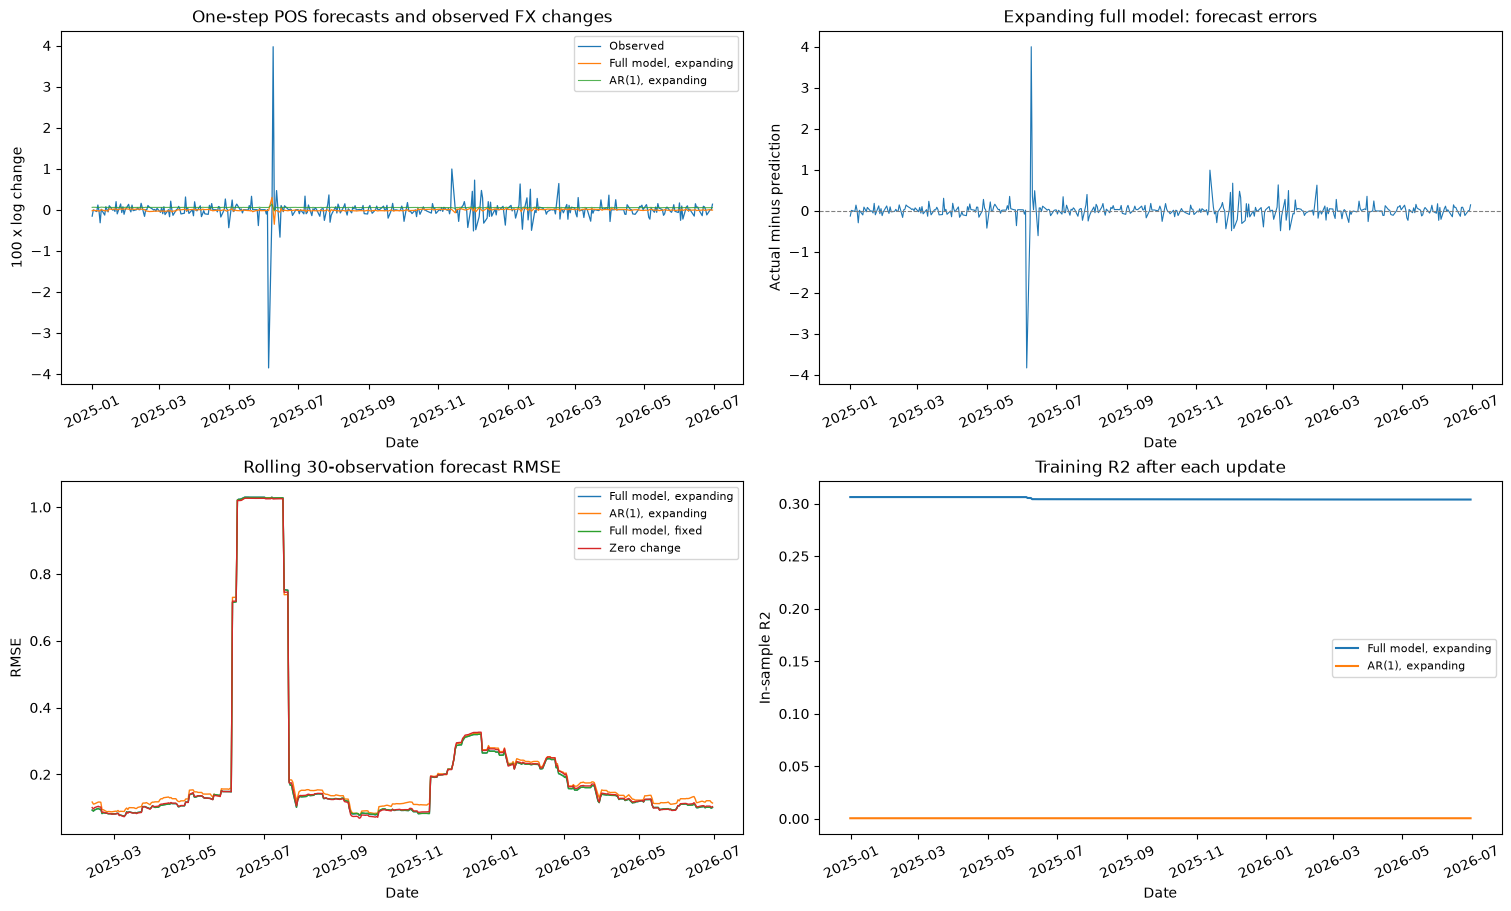

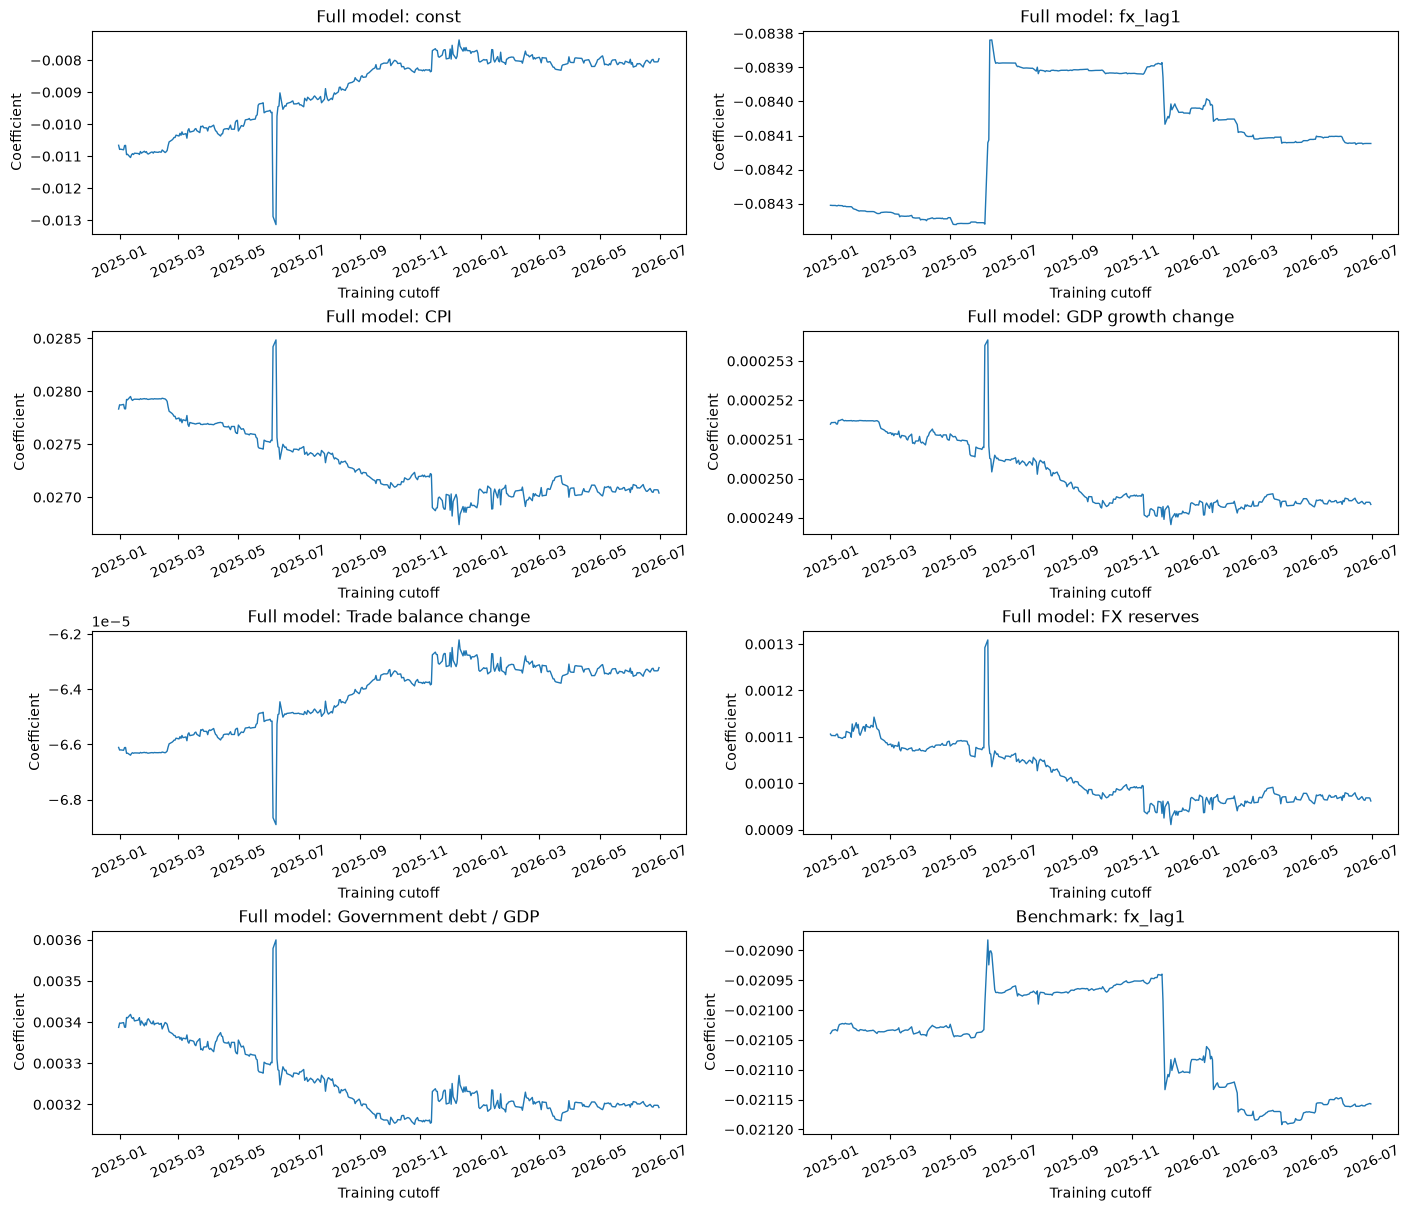

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9), layout="constrained")
axes[0, 0].plot(forecast_log.index, forecast_log["actual"], label="Observed", linewidth=0.9)
axes[0, 0].plot(
    forecast_log.index, forecast_log["prediction::full_expanding"],
    label="Full model, expanding", linewidth=0.9,
)
axes[0, 0].plot(
    forecast_log.index, forecast_log["prediction::ar1_expanding"],
    label="AR(1), expanding", linewidth=0.8, alpha=0.8,
)
axes[0, 0].set(title="One-step POS forecasts and observed FX changes", ylabel="100 x log change")
axes[0, 0].legend(fontsize=8)
axes[0, 1].plot(
    forecast_log.index, forecast_log["error::full_expanding"], linewidth=0.8
)
axes[0, 1].axhline(0, color="grey", linestyle="--", linewidth=0.8)
axes[0, 1].set(title="Expanding full model: forecast errors", ylabel="Actual minus prediction")

for model_key, label in MODEL_LABELS.items():
    axes[1, 0].plot(
        running_accuracy.index,
        running_accuracy[f"rolling_{ROLLING_OBSERVATIONS}obs_RMSE::{model_key}"],
        label=label, linewidth=1,
    )
axes[1, 0].set(title=f"Rolling {ROLLING_OBSERVATIONS}-observation forecast RMSE", ylabel="RMSE")
axes[1, 0].legend(fontsize=8)
for model_key in ["full_expanding", "ar1_expanding"]:
    history = training_history.loc[training_history["model"].eq(model_key)]
    axes[1, 1].plot(history["fit_through"], history["training_R2"], label=MODEL_LABELS[model_key])
axes[1, 1].set(title="Training R2 after each update", ylabel="In-sample R2")
axes[1, 1].legend(fontsize=8)
for ax in axes.flat:
    ax.set_xlabel("Date")
    ax.tick_params(axis="x", labelrotation=25)
plt.show()

full_parameters = parameter_history.loc[
    parameter_history["model"].eq("full_expanding")
].set_index("fit_through")
ar1_parameters = parameter_history.loc[
    parameter_history["model"].eq("ar1_expanding")
].set_index("fit_through")
fig, axes = plt.subplots(4, 2, figsize=(14, 12), layout="constrained")
for ax, term in zip(axes.flat, ["const", *continuous]):
    ax.plot(full_parameters.index, full_parameters[term], linewidth=1)
    ax.set(title=f"Full model: {term}", ylabel="Coefficient")
axes.flat[-1].plot(
    ar1_parameters.index, ar1_parameters["fx_lag1"], label="AR(1) benchmark", linewidth=1
)
axes.flat[-1].set(title="Benchmark: fx_lag1", ylabel="Coefficient")
for ax in axes.flat:
    ax.set_xlabel("Training cutoff")
    ax.tick_params(axis="x", labelrotation=25)
plt.show()
